# CA1: Adult Income – Data Exploration and Preparation
**Domain:** Population and Society  
**Dataset:** UCI Adult (Census Income), Becker and Kohavi (1996)  
**Source:** https://archive.ics.uci.edu/dataset/2/adult

- **Part A:** motivation, source and reference, and what each column means
- **Part B (Task 1):** data preparation: size, attributes, missing values, duplicates, outliers, feature engineering and challenges
- **Part C (Task 2):** exploratory data analysis: variation, covariation, four questions, unusual patterns and findings
- **Part D (Task 3):** encoding and Principal Component Analysis (PCA)

# Part A: Problem Domain and Dataset

## A1. Problem domain and motivation
I chose the **Population and Society** domain because income inequality affects almost every country, including Pakistan. People often assume that education and hard work decide how much someone earns, but factors such as gender, race, marital status and type of job may also play a large part. I wanted to test these ideas with real data rather than opinion.

The **UCI Adult (Census Income)** dataset suits this goal well. It contains real records from the 1994 US Census for about 48,000 people, with a clear outcome (whether a person earns more than $50,000 a year) and a mix of personal and work details. It also has missing values and outliers, so it gives a realistic chance to practise data cleaning, and it has both text and numeric columns for encoding and PCA.

**Problem to explore:** Which demographic and employment factors are most strongly linked to earning more than $50K a year, and are there clear income gaps by gender, race or education level?

## A2. Source and Harvard reference
**Link:** https://archive.ics.uci.edu/dataset/2/adult

**Harvard reference:**  
Becker, B. and Kohavi, R. (1996) *Adult* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C5XW20 (Accessed: 17 November 2026).

In-text: (Becker and Kohavi, 1996)

## A3. What each column means

| Column | Type | Meaning |
|---|---|---|
| age | Numeric | Age of the person in years |
| workclass | Categorical | Type of employer (private, self-employed, government, etc.) |
| fnlwgt | Numeric | **Census sampling weight**: roughly how many people in the US population this record represents. It describes the sample, **not a characteristic of the person**, so it is usually left out of analysis and PCA. |
| education | Categorical | Highest education level as text (e.g. Bachelors, HS-grad) |
| education_num | Numeric | The same education level as a number (1 = Preschool … 16 = Doctorate). **It holds the same information as `education`**, so only one of the two should be used in modelling and PCA. |
| marital_status | Categorical | Marital status (married, never married, divorced, etc.) |
| occupation | Categorical | Type of job (e.g. Tech-support, Sales, Craft-repair) |
| relationship | Categorical | Role in the household (husband, wife, own-child, etc.) |
| race | Categorical | Race recorded in the census |
| sex | Categorical | Male or Female |
| capital_gain | Numeric | Income from investments (e.g. selling shares), in US dollars |
| capital_loss | Numeric | Losses from investments, in US dollars |
| hours_per_week | Numeric | Hours worked per week |
| native_country | Categorical | Country of birth |
| income | Categorical (target) | Whether yearly income is `<=50K` or `>50K` US dollars |

# Part B: Data Preparation (Task 1)

## B0. Load the raw data

In [ ]:
# --- Import libraries ---
import io                         # treat downloaded bytes like a file
import zipfile                    # open the .zip file from UCI
import urllib.request             # download from the web
import numpy as np                # numeric functions
import pandas as pd               # tables (DataFrames)
import matplotlib.pyplot as plt   # charts

URL = "https://archive.ics.uci.edu/static/public/2/adult.zip"
COLUMNS = ["age", "workclass", "fnlwgt", "education", "education_num",
           "marital_status", "occupation", "relationship", "race", "sex",
           "capital_gain", "capital_loss", "hours_per_week", "native_country",
           "income"]

# Download the zip file into memory
z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read()))

def read_part(name, skip, na=None):
    """Read one file from the zip.
    skip = junk lines at the top (adult.test has 1).
    na   = which text should count as a missing value (None = nothing)."""
    return pd.read_csv(io.TextIOWrapper(z.open(name)), header=None, names=COLUMNS,
                       skiprows=skip, skipinitialspace=True, na_values=na)

# Read the train and test files EXACTLY as they are (no cleaning yet),
# so we can show the problems in the raw data
raw = pd.concat([read_part("adult.data", 0), read_part("adult.test", 1)],
                ignore_index=True)
# Save a copy of the original data (only the income full stop fixed)
raw_out = raw.copy()
raw_out["income"] = raw_out["income"].str.rstrip(".")
raw_out.to_csv("adult_raw.csv", index=False)
print("Saved adult_raw.csv")
raw.head()

Saved adult_raw.csv


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## B1. Size before cleaning
`.shape` gives (rows, columns). The train and test files together hold the full dataset.

In [ ]:
# Size of the raw dataset
print("Raw shape (rows, columns):", raw.shape)

Raw shape (rows, columns): (48842, 15)


## B2. Attributes (columns)
### B2.1 Column types
`.info()` shows each column's data type. Text columns (`object`) are **categorical**; integer columns are **numeric**.

In [ ]:
# Data type of every column and the number of non-empty values
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       48842 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education_num   48842 non-null  int64 
 5   marital_status  48842 non-null  object
 6   occupation      48842 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital_gain    48842 non-null  int64 
 11  capital_loss    48842 non-null  int64 
 12  hours_per_week  48842 non-null  int64 
 13  native_country  48842 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [ ]:
# Number of different values in each column
# (helps decide how categorical columns will be encoded later in Task 3)
raw.nunique().sort_values()

,0
sex,2
income,4
race,5
relationship,6
marital_status,7
workclass,9
occupation,15
education,16
education_num,16
native_country,42


In [ ]:
# Summary statistics for the numeric columns (min, max, mean, quartiles)
raw.describe().round(1)

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,48842.0,48842.0,48842.0,48842.0,48842.0,48842.0
mean,38.6,189664.1,10.1,1079.1,87.5,40.4
std,13.7,105604.0,2.6,7452.0,403.0,12.4
min,17.0,12285.0,1.0,0.0,0.0,1.0
25%,28.0,117550.5,9.0,0.0,0.0,40.0
50%,37.0,178144.5,10.0,0.0,0.0,40.0
75%,48.0,237642.0,12.0,0.0,0.0,45.0
max,90.0,1490400.0,16.0,99999.0,4356.0,99.0


### B2.2 Columns that will be removed (and why)
**`education` and `education_num` hold the same information.** `education` is the level as text (e.g. *Bachelors*) and `education_num` is the same level as a number (e.g. 13). The code below proves that each text level maps to exactly one number. We keep `education_num`, because it is already numeric and keeps the natural order of levels (Preschool < … < Doctorate), and remove `education`.

**`fnlwgt` is a census sampling weight**, not a feature of the person. It tells us how many people in the US population a record represents. The code below shows it has almost no link with income.

In [ ]:
# Each education text level should map to ONE education_num value
mapping = raw.groupby("education")["education_num"].unique().sort_values()
print(mapping)
print("\nEvery level maps to exactly one number:",
      raw.groupby("education")["education_num"].nunique().eq(1).all())

education
Preschool        [1]
1st-4th          [2]
5th-6th          [3]
7th-8th          [4]
9th              [5]
10th             [6]
11th             [7]
12th             [8]
HS-grad          [9]
Some-college    [10]
Assoc-voc       [11]
Assoc-acdm      [12]
Bachelors       [13]
Masters         [14]
Prof-school     [15]
Doctorate       [16]
Name: education_num, dtype: object

Every level maps to exactly one number: True


In [ ]:
# Correlation between fnlwgt and income (1 = >50K, 0 = <=50K).
# A value close to 0 means fnlwgt tells us almost nothing about income.
income_01 = raw["income"].str.contains(">50K").astype(int)
print("Correlation of fnlwgt with income:", round(raw["fnlwgt"].corr(income_01), 4))

Correlation of fnlwgt with income: -0.0063


*These two columns are removed in section B4.2, after duplicates are checked (the order matters: see challenge 4).*

## B3. Missing values
### B3.1 Finding hidden missing values
In the raw files, missing values are written as **`?`**, not left empty. Pandas therefore reads them as normal text, and `.isna()` reports **no missing values at all**, even though data is missing.

In [ ]:
# Pandas thinks nothing is missing...
print("Missing values found by isna():", raw.isna().sum().sum())

# ...but the '?' symbol appears in several columns
print("\nCount of '?' in each column:")
q = (raw == "?").sum()
print(q[q > 0])

Missing values found by isna(): 0

Count of '?' in each column:
workclass         2799
occupation        2809
native_country     857
dtype: int64


### B3.2 Fixing the labels and the '?' values
Two fixes are applied to the raw data:
- **`?` → NaN**, so pandas recognises the values as missing.
- **Income labels:** the test file writes `>50K.` and `<=50K.` with a full stop, so the target column has **4 labels instead of 2**. The full stop is removed.

In [ ]:
# The income column has 4 labels before the fix
print("Income labels BEFORE:", raw["income"].unique())

df = raw.copy()                              # work on a copy; keep raw unchanged
df = df.replace("?", np.nan)                 # mark '?' as a real missing value
df["income"] = df["income"].str.rstrip(".")  # '>50K.' -> '>50K'

print("Income labels AFTER: ", df["income"].unique())

Income labels BEFORE: ['<=50K' '>50K' '<=50K.' '>50K.']
Income labels AFTER:  ['<=50K' '>50K']


### B3.3 How much is missing?

In [ ]:
# Missing values per column, as a count and as a percentage of all rows
missing = df.isna().sum()
missing = missing[missing > 0]
print(pd.DataFrame({"missing": missing,
                    "percent": (missing / len(df) * 100).round(2)}))

rows_missing = df.isna().any(axis=1).sum()   # rows with at least one gap
print(f"\nRows with at least one missing value: {rows_missing:,} "
      f"({rows_missing / len(df) * 100:.2f}% of all rows)")

                missing  percent
workclass          2799     5.73
occupation         2809     5.75
native_country      857     1.75

Rows with at least one missing value: 3,620 (7.41% of all rows)


### B3.4 Are the values missing at random?
Before choosing a method, we check *where* the gaps are. If `workclass` and `occupation` are usually missing together, the gap is probably about people who were not working, not random errors.

In [ ]:
# How often workclass and occupation are missing together
print(pd.crosstab(df["workclass"].isna(), df["occupation"].isna(),
                  rownames=["workclass missing"], colnames=["occupation missing"]))

# Rows where occupation is missing but workclass is NOT: what is their workclass?
print("\nWorkclass when only occupation is missing:")
print(df.loc[df["occupation"].isna() & df["workclass"].notna(), "workclass"].value_counts())

occupation missing  False  True 
workclass missing               
False               46033     10
True                    0   2799

Workclass when only occupation is missing:
workclass
Never-worked    10
Name: count, dtype: int64


In [ ]:
# Does the share of high earners differ between rows with and without gaps?
has_gap = df.isna().any(axis=1)
print("Share earning >50K")
print("  rows WITH missing values:   ", round((df.loc[has_gap,  "income"] == ">50K").mean(), 3))
print("  rows WITHOUT missing values:", round((df.loc[~has_gap, "income"] == ">50K").mean(), 3))

Share earning >50K
  rows WITH missing values:    0.132
  rows WITHOUT missing values: 0.248


### B3.5 Handling the missing values: `dropna()`
**Method chosen: remove rows with missing values (`dropna()`).**

**Why:**
- The missing values are all in **categorical** columns, so mean or median filling is not possible.
- Only about **7% of rows** are affected, so more than 45,000 rows remain, far above the 3,000 minimum.
- Filling with `"Unknown"` would add an artificial category to three columns. That category would be mixed with real ones during encoding and PCA in Task 3, and it has no clear meaning.
- Filling with the **mode** (most common value) would wrongly label people who were not working as, for example, *Private* employees.

**Trade-off:** section B3.4 shows the gaps are **not completely random**. `workclass` and `occupation` are mostly missing together, and the rows with gaps contain fewer high earners. Dropping them may slightly under-represent people outside regular work. Because the loss is small and the dataset stays large, this is accepted and noted as a limitation.

In [ ]:
before = len(df)
df = df.dropna()                     # remove every row that has a missing value
print(f"Rows removed: {before - len(df):,}")
print("Missing values left:", df.isna().sum().sum())
print("Shape now:", df.shape)

Rows removed: 3,620
Missing values left: 0
Shape now: (45222, 15)


## B4. Duplicates and redundant columns
### B4.1 Removing duplicate rows
Exact duplicate rows add no information and would give some people extra weight in the analysis. They are checked **before** `fnlwgt` is removed (see challenge 4).

In [ ]:
# Count rows that are exact copies of an earlier row (all 15 columns equal)
n_dup = df.duplicated().sum()
print("Exact duplicate rows:", n_dup)

# Show a few of them
df[df.duplicated(keep=False)].sort_values(COLUMNS).head(6)

Exact duplicate rows: 47


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
24667,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
36713,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
36461,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
48521,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
17673,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
18698,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K


In [ ]:
before = len(df)
df = df.drop_duplicates()            # keep the first copy, remove the rest
print(f"Duplicate rows removed: {before - len(df):,}")
dup_left = df.duplicated().sum()     # should be 0; saved for the summary table
print("Exact duplicates left:", dup_left)
print("Shape now:", df.shape)

Duplicate rows removed: 47
Exact duplicates left: 0
Shape now: (45175, 15)


### B4.2 Removing `fnlwgt` and `education`

In [ ]:
# Why the order matters: WITHOUT fnlwgt, many different people look identical
print("Rows that would look like duplicates if fnlwgt were removed first:",
      df.drop(columns=["fnlwgt", "education"]).duplicated().sum())

# Remove the two columns explained in section B2.2
df = df.drop(columns=["fnlwgt", "education"])
print("\nShape after removing columns:", df.shape)
print("Remaining columns:", df.columns.tolist())

Rows that would look like duplicates if fnlwgt were removed first: 5935

Shape after removing columns: (45175, 13)
Remaining columns: ['age', 'workclass', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']


## B5. Out-of-range data and outliers
### B5.1 Out-of-range (invalid) values
First, check that every value is **possible**. For example, an age must be within a sensible working range and hours per week cannot be more than 168.

In [ ]:
# Sensible limits for each numeric column
limits = {"age": (17, 100), "education_num": (1, 16),
          "capital_gain": (0, 100000), "capital_loss": (0, 100000),
          "hours_per_week": (1, 168)}

# Count values outside the limits
for col, (lo, hi) in limits.items():
    bad = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col:15s} allowed {lo}-{hi:<7}  min={df[col].min():<6} max={df[col].max():<6} invalid={bad}")

age             allowed 17-100      min=17     max=90     invalid=0
education_num   allowed 1-16       min=1      max=16     invalid=0
capital_gain    allowed 0-100000   min=0      max=99999  invalid=0
capital_loss    allowed 0-100000   min=0      max=4356   invalid=0
hours_per_week  allowed 1-168      min=1      max=99     invalid=0


### B5.2 Outliers with the IQR method
A value is an outlier if it is more than 1.5 × IQR below Q1 or above Q3.

In [ ]:
num_cols = df.select_dtypes(include="number").columns   # numeric columns only
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])            # 1st and 3rd quartiles
    iqr = q3 - q1                                    # interquartile range
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr          # outlier limits
    n = ((df[c] < lo) | (df[c] > hi)).sum()          # count outside limits
    rows.append([c, q1, q3, iqr, n, round(n / len(df) * 100, 2)])

iqr_table = pd.DataFrame(rows, columns=["column", "Q1", "Q3", "IQR", "outliers", "% of rows"])
iqr_table

,column,Q1,Q3,IQR,outliers,% of rows
0,age,28.0,47.0,19.0,268,0.59
1,education_num,9.0,13.0,4.0,290,0.64
2,capital_gain,0.0,0.0,0.0,3790,8.39
3,capital_loss,0.0,0.0,0.0,2140,4.74
4,hours_per_week,40.0,45.0,5.0,11889,26.32


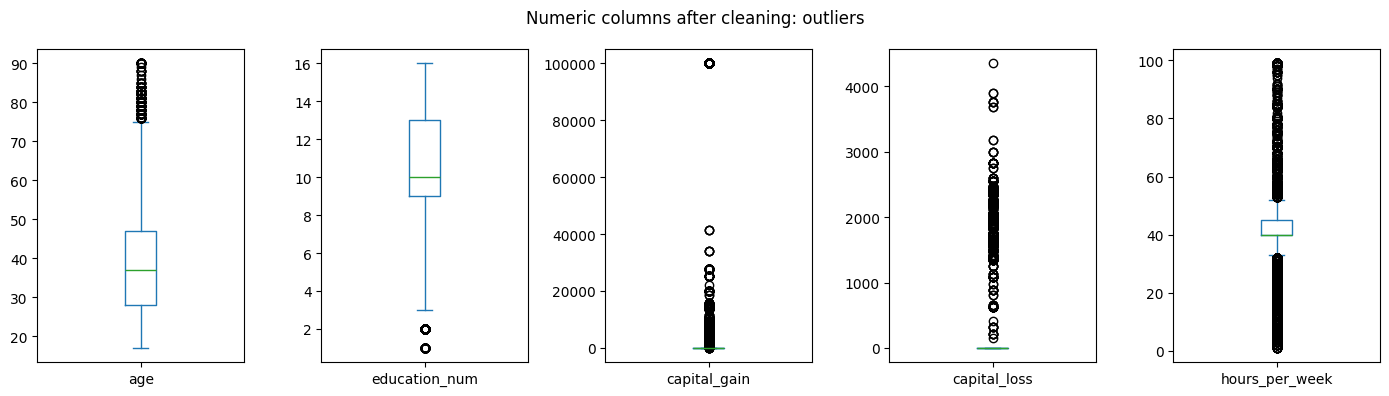

In [ ]:
# Box plots: dots beyond the whiskers are IQR outliers
df[num_cols].plot(kind="box", subplots=True, layout=(1, len(num_cols)),
                  figsize=(14, 4), sharey=False)
plt.suptitle("Numeric columns after cleaning: outliers")
plt.tight_layout(); plt.show()

### B5.3 Checking the suspicious values
Some extreme values look like **caps**, where the census recorded one top value for everyone above it, rather than errors.

In [ ]:
# capital_gain: how many zeros, and how many exactly 99,999?
print(f"capital_gain = 0:      {(df['capital_gain'] == 0).mean() * 100:.1f}% of rows")
print(f"capital_gain = 99,999: {(df['capital_gain'] == 99999).sum()} rows")
print("Next-highest capital_gain after 99,999:",
      df.loc[df["capital_gain"] < 99999, "capital_gain"].max())

# hours_per_week = 99 and age = 90 (the highest values in each column)
print(f"\nhours_per_week = 99: {(df['hours_per_week'] == 99).sum()} rows")
print(f"age = 90:            {(df['age'] == 90).sum()} rows")

# What share of people with capital_gain = 99,999 earn >50K?
print("\nShare earning >50K when capital_gain = 99,999:",
      round((df.loc[df['capital_gain'] == 99999, 'income'] == ">50K").mean(), 3))

capital_gain = 0:      91.6% of rows
capital_gain = 99,999: 229 rows
Next-highest capital_gain after 99,999: 41310

hours_per_week = 99: 123 rows
age = 90:            45 rows

Share earning >50K when capital_gain = 99,999: 1.0


### B5.4 Decision: keep the outliers
**All outliers are kept. No rows are removed or capped.**

**Why:**
- Section B5.1 found **no invalid values**. Every value is possible, so these are real but rare observations, not errors.
- **`capital_gain`:** most values are 0, so Q1 = Q3 = 0 and the IQR is 0. The IQR rule then marks *every* non-zero value as an outlier. Removing them would delete almost everyone with investment income, and those people are mostly high earners, which is exactly the group we study. The value **99,999 is a census cap** (there is a large gap below it), so it means "very high gain", not a typing error.
- **`hours_per_week = 99`** and **`age = 90`** are the highest values the census recorded (caps). Some people really do work very long hours, and people aged 90 exist.
- **Capping** (for example with `.clip()`) would hide real differences between people with high incomes.

To reduce the effect of the very skewed capital columns in later tasks, section B6 adds a simple yes/no feature. PCA in Task 3 will also use **scaled** values.

## B6. Feature engineering
New columns are created to make the data easier to analyse and model:
1. **`income` → 0/1**: models and correlation need a numeric target (1 = earns >50K).
2. **`age_group`**: groups ages into ranges with `pd.cut()`, which are easier to compare in charts than 70+ single ages.
3. **`has_capital_gain`**: 1 if the person had any investment income. This keeps the useful signal from the very skewed `capital_gain` column in a simple form.

In [ ]:
# 1. Income as 0/1
df["income"] = (df["income"] == ">50K").astype(int)
print("Income value counts (0 = <=50K, 1 = >50K):")
print(df["income"].value_counts())
print(f"Share of >50K: {df['income'].mean() * 100:.1f}%  <- the classes are imbalanced")

Income value counts (0 = <=50K, 1 = >50K):
income
0    33973
1    11202
Name: count, dtype: int64
Share of >50K: 24.8%  <- the classes are imbalanced


In [ ]:
# 2. Age groups (bins are 'right-closed': (16, 25] means 17-25)
bins   = [16, 25, 35, 45, 55, 65, 100]
labels = ["17-25", "26-35", "36-45", "46-55", "56-65", "66+"]
df["age_group"] = pd.cut(df["age"], bins=bins, labels=labels)

# 3. Any capital gain? (1 = yes, 0 = no)
df["has_capital_gain"] = (df["capital_gain"] > 0).astype(int)

# Check: share of high earners in each age group and by capital gain
print(df.groupby("age_group", observed=True)["income"].mean().round(3))
print()
print(df.groupby("has_capital_gain")["income"].mean().round(3))

age_group
17-25    0.019
26-35    0.191
36-45    0.350
46-55    0.397
56-65    0.322
66+      0.217
Name: income, dtype: float64

has_capital_gain
0    0.213
1    0.627
Name: income, dtype: float64


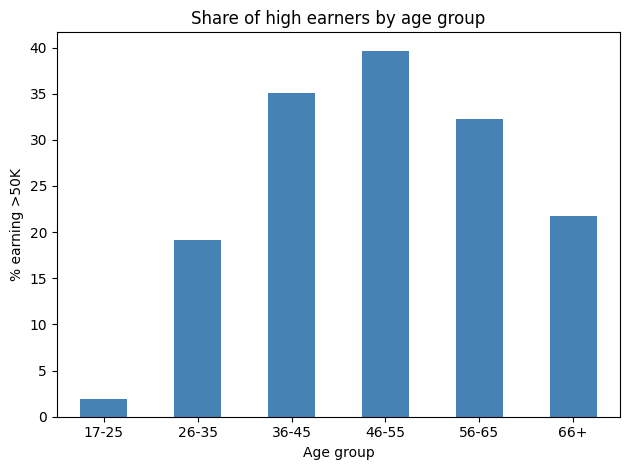

In [ ]:
# Bar chart: the new age_group feature clearly separates income levels
df.groupby("age_group", observed=True)["income"].mean().mul(100).plot(kind="bar", color="steelblue")
plt.ylabel("% earning >50K"); plt.xlabel("Age group")
plt.title("Share of high earners by age group")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## B7. Before/after summary table

In [ ]:
from IPython.display import Markdown, display

raw_fixed = raw.replace("?", np.nan)                     # '?' counted as missing
raw_fixed["income"] = raw_fixed["income"].str.rstrip(".")  # same labels, so duplicates are compared fairly
summary = pd.DataFrame({
    "Before cleaning": [f"{raw.shape[0]:,}", raw.shape[1],
                        f"{raw_fixed.isna().sum().sum():,}",
                        f"{raw_fixed.isna().any(axis=1).sum():,}",
                        f"{raw_fixed.duplicated().sum():,}",
                        raw["income"].nunique()],
    "After cleaning": [f"{df.shape[0]:,}", df.shape[1],
                       df.isna().sum().sum(), 0,
                       dup_left,
                       df["income"].nunique()],
}, index=["Rows", "Columns", "Missing values (cells)", "Rows with missing values",
          "Exact duplicate rows", "Income labels"])

display(summary)
print(f"Columns after: 13 original + 2 engineered (age_group, has_capital_gain) = {df.shape[1]}")
print(f"Rows kept: {df.shape[0] / raw.shape[0] * 100:.1f}% of the original data")

,Before cleaning,After cleaning
Rows,"48,842","45,175"
Columns,15,15
Missing values (cells),"6,465",0
Rows with missing values,"3,620",0
Exact duplicate rows,52,0
Income labels,4,2


Columns after: 13 original + 2 engineered (age_group, has_capital_gain) = 15
Rows kept: 92.5% of the original data


## B8. Challenges (critical discussion)

**1. Missing values were hidden as `?`.**
*Problem:* The files use `?` with a leading space for missing values, so pandas read them as normal text and `.isna()` reported zero missing values (section B3.1). If this had gone unnoticed, `?` would have become a fake category in `workclass`, `occupation` and `native_country`, and would later have been encoded as if it were a real job type.
*Solution:* `skipinitialspace=True` removed the spaces, and `?` was replaced with NaN.
*Effect:* The real extent of missing data (about 7% of rows) became visible, which made an informed decision possible.

**2. Choosing how to handle missing values.**
*Problem:* Dropping rows loses data, but filling them adds guesses. Section B3.4 showed the gaps are **not random**: `workclass` and `occupation` are mostly missing together, and these rows contain fewer high earners, so they probably describe people outside regular work.
*Solution:* `dropna()` was chosen because the columns are categorical and the loss is small, while `"Unknown"` or mode filling would distort the categories.
*Effect:* The data is complete and still large, but it may slightly under-represent people who were not working. This is a known limitation of the results.

**3. Inconsistent target labels.**
*Problem:* The test file writes `>50K.` with a full stop, so the target had 4 labels instead of 2. A model would treat `>50K` and `>50K.` as different classes, and about a third of the data would be labelled wrongly.
*Solution:* `.str.rstrip(".")` removed the full stop before anything else was done.
*Effect:* One consistent target, which was then converted to 0/1.

**4. The order of cleaning steps changed the result.**
*Problem:* `fnlwgt` makes almost every row unique. Once it is removed, many *different* people share the same age, job, hours and so on, and would look like duplicates (section B4.2 shows how many).
*Solution:* Exact duplicates were removed **before** dropping `fnlwgt`, so only true copies were deleted.
*Effect:* Many genuine records were kept that a careless order would have deleted (the exact number is shown in section B4.2).

**5. The IQR rule was misleading for skewed columns.**
*Problem:* Most `capital_gain` and `capital_loss` values are 0, so the IQR is 0 and every non-zero value is called an outlier. The value 99,999 is a census cap, not a measurement.
*Solution:* Outliers were judged by meaning, not only by the formula: they are all valid values, so they were kept, and a simpler `has_capital_gain` feature was added.
*Effect:* High earners stay in the data, but the skew remains, so scaling will be needed before PCA.

**Wider limitation:** The data is from **1994** and covers only the **USA**. Incomes, jobs and social patterns have changed since then, and results may not apply to other countries such as Pakistan today. The target is also **imbalanced** (only about a quarter earn >50K), which must be kept in mind when evaluating models in later tasks.

## B9. Save and download the data

In [ ]:
# Save the cleaned dataset for the next tasks
df.to_csv("adult_clean.csv", index=False)
print("Saved adult_clean.csv with shape", df.shape)

Saved adult_clean.csv with shape (45175, 15)


In [ ]:
# Download the original data
from google.colab import files
files.download("adult_raw.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Download the cleaned data
from google.colab import files
files.download("adult_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part C: Exploratory Data Analysis (Task 2)
This part looks for **variation** (how one column is spread), **covariation** (how two columns move together) and **unusual patterns**, and answers four questions about **income inequality** with charts.

## C0. Load the clean data

In [ ]:
# --- Libraries for the EDA ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")          # clean background with grid lines
plt.rcParams["figure.dpi"] = 100          # sharper charts

# Load the cleaned data saved at the end of Part B
df = pd.read_csv("adult_clean.csv")

# After reading a CSV, age_group is plain text. Give it its natural order again.
age_order = ["17-25", "26-35", "36-45", "46-55", "56-65", "66+"]
df["age_group"] = pd.Categorical(df["age_group"], categories=age_order, ordered=True)

# education_num 1-16 -> readable names (used for chart labels)
edu_names = {1: "Preschool", 2: "1st-4th", 3: "5th-6th", 4: "7th-8th", 5: "9th",
             6: "10th", 7: "11th", 8: "12th", 9: "HS-grad", 10: "Some-college",
             11: "Assoc-voc", 12: "Assoc-acdm", 13: "Bachelors", 14: "Masters",
             15: "Prof-school", 16: "Doctorate"}

print("Shape:", df.shape)
df.head()

Shape: (45175, 15)


,age,workclass,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,age_group,has_capital_gain
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0,36-45,1
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0,46-55,0
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0,36-45,0
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0,46-55,0
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0,26-35,0


## C1. Variation: one column at a time
### C1.1 Numeric columns

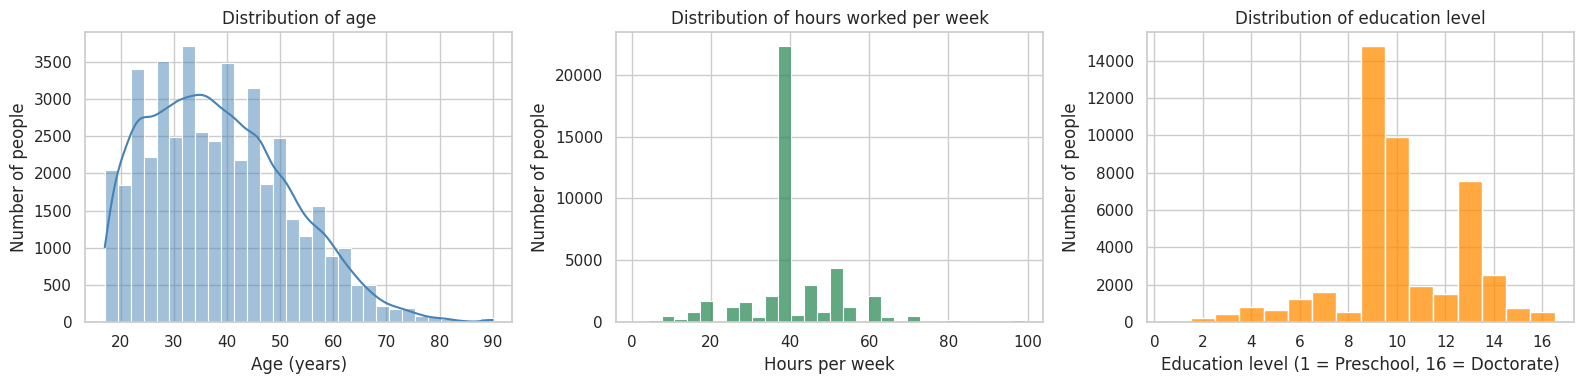

Age: median 37, skewness 0.53, share aged 25-45: 54.6%
Hours: exactly 40 hours = 47.2% of people
Most common education levels (%): {'HS-grad': 32.7, 'Some-college': 21.9, 'Bachelors': 16.7}


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Age: histogram with a smooth density line (kde)
sns.histplot(df["age"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set(title="Distribution of age", xlabel="Age (years)", ylabel="Number of people")

# Hours per week
sns.histplot(df["hours_per_week"], bins=30, ax=axes[1], color="seagreen")
axes[1].set(title="Distribution of hours worked per week", xlabel="Hours per week", ylabel="Number of people")

# Education level (discrete 1-16, so one bar per level)
sns.histplot(df["education_num"], discrete=True, ax=axes[2], color="darkorange")
axes[2].set(title="Distribution of education level", xlabel="Education level (1 = Preschool, 16 = Doctorate)",
            ylabel="Number of people")

plt.tight_layout(); plt.show()

# Figures used in the interpretation
print(f"Age: median {df['age'].median():.0f}, skewness {df['age'].skew():.2f}, "
      f"share aged 25-45: {df['age'].between(25, 45).mean()*100:.1f}%")
print(f"Hours: exactly 40 hours = {(df['hours_per_week'] == 40).mean()*100:.1f}% of people")
top_edu = df["education_num"].map(edu_names).value_counts(normalize=True).head(3).mul(100).round(1)
print("Most common education levels (%):", top_edu.to_dict())

**Interpretation:**
- **Age** is **right-skewed** (positive skewness): most people are aged about 25–45, and the number falls steadily after 50.
- **Hours per week** has a very tall, narrow peak at **40 hours** (the standard full-time week). Variation around it is small, with a few people working very short or very long weeks.
- **Education** is concentrated at three levels: **HS-grad**, **Some-college** and **Bachelors**. Very few people have a doctorate or less than 9th-grade education.

### C1.2 Categorical columns

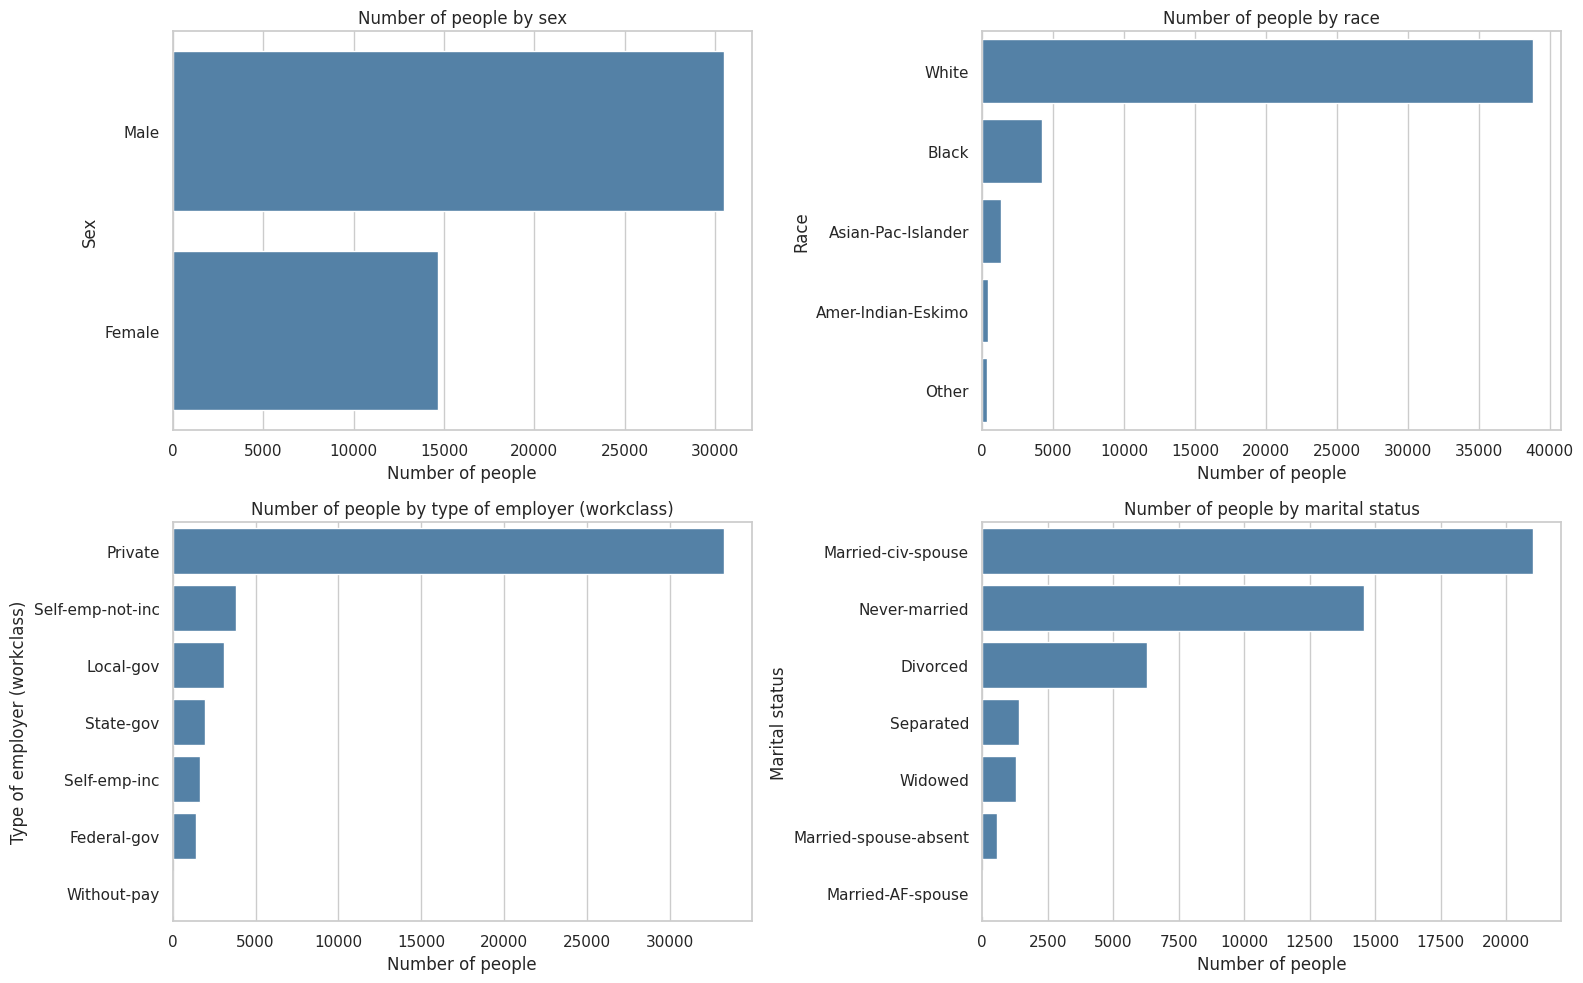

sex {'Male': 67.5, 'Female': 32.5}
race {'White': 86.0, 'Black': 9.4, 'Asian-Pac-Islander': 2.9}
workclass {'Private': 73.6, 'Self-emp-not-inc': 8.4, 'Local-gov': 6.9}
marital_status {'Married-civ-spouse': 46.6, 'Never-married': 32.2, 'Divorced': 13.9}


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# order=... sorts bars from most to least common
for ax, col, title in zip(axes.flat,
                          ["sex", "race", "workclass", "marital_status"],
                          ["Sex", "Race", "Type of employer (workclass)", "Marital status"]):
    sns.countplot(data=df, y=col, order=df[col].value_counts().index, ax=ax, color="steelblue")
    ax.set(title=f"Number of people by {title.lower()}", xlabel="Number of people", ylabel=title)

plt.tight_layout(); plt.show()

# Shares (%) used in the interpretation
for col in ["sex", "race", "workclass", "marital_status"]:
    print(col, df[col].value_counts(normalize=True).mul(100).round(1).head(3).to_dict())

**Interpretation:**
- **Sex:** men outnumber women by about **2 to 1**, so the sample is not balanced by sex.
- **Race:** the large majority of people are **White**; other groups are small, so results for them are less reliable.
- **Workclass:** most people work in the **Private** sector, far ahead of self-employment and government jobs.
- **Marital status:** **Married-civ-spouse** (married, living with a spouse) and **Never-married** are the two largest groups.

### C1.3 Income (the target)

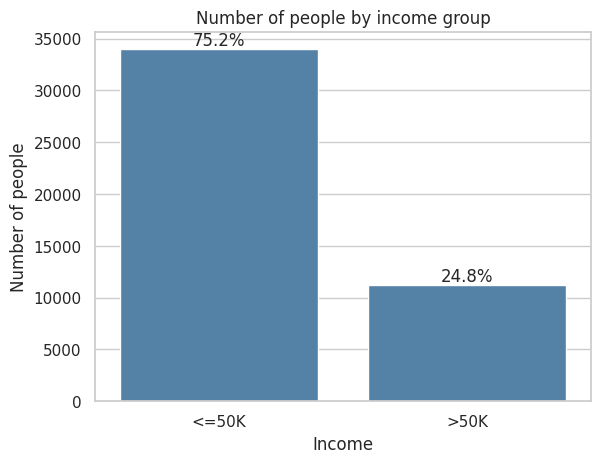

In [ ]:
ax = sns.countplot(data=df, x="income", color="steelblue")
ax.set(title="Number of people by income group", xlabel="Income", ylabel="Number of people")
ax.set_xticks([0, 1], ["<=50K", ">50K"])

# Write the percentage on top of each bar
shares = df["income"].value_counts(normalize=True).sort_index() * 100
for i, s in enumerate(shares):
    ax.text(i, ax.patches[i].get_height(), f"{s:.1f}%", ha="center", va="bottom", fontsize=12)
plt.show()

**Interpretation:** the classes are **imbalanced**: about **three quarters** of people earn <=50K and about **one quarter** earn >50K. A model that always guessed "<=50K" would already be right about 75% of the time, so accuracy alone will be misleading in later tasks.

## C2. Covariation: two columns together
### C2.1 Correlation heatmap (numeric columns)

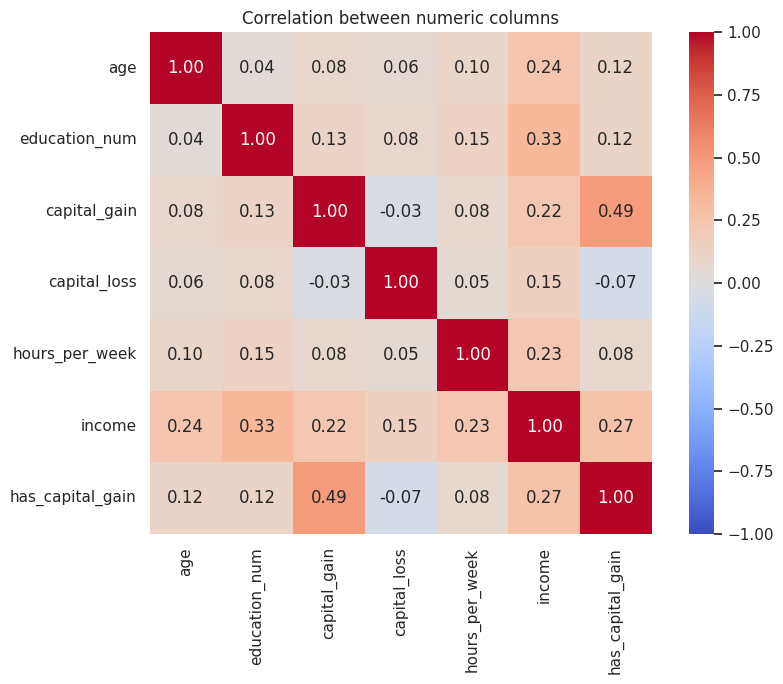

Correlation with income:
education_num       0.333
has_capital_gain    0.265
age                 0.237
hours_per_week      0.227
capital_gain        0.221
capital_loss        0.149
Name: income, dtype: float64


**Order of correlation with income (strongest first):** `education_num` (0.33), `has_capital_gain` (0.27), `age` (0.24), `hours_per_week` (0.23), `capital_gain` (0.22), `capital_loss` (0.15)

In [ ]:
corr = df.corr(numeric_only=True)      # Pearson correlation between every pair of numeric columns

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation between numeric columns")
plt.tight_layout(); plt.show()

# Correlation of each column with income, strongest first
print("Correlation with income:")
print(corr["income"].drop("income").sort_values(ascending=False).round(3))

# Show the order of correlation with income as text
from IPython.display import Markdown, display
order = corr["income"].drop("income").sort_values(ascending=False)
display(Markdown("**Order of correlation with income (strongest first):** " +
                 ", ".join(f"`{k}` ({v:.2f})" for k, v in order.items())))

**Interpretation:**
- No numeric column has a **strong** correlation with income on its own. The exact order is printed under the heatmap. **education_num**, **age**, **hours_per_week** and the capital-gain columns all have **positive** correlations: more education, more experience and longer hours go with higher income.
- **capital_gain** and **has_capital_gain** are linked because one was created from the other (Part B6), so only one of them should be used together in a model.
- The numeric columns are only weakly related **to each other**, which means each one brings different information. This matters for PCA in Task 3.
- Correlation only measures **straight-line** relationships and cannot include categorical columns such as sex or marital status, so these are explored with the questions below.

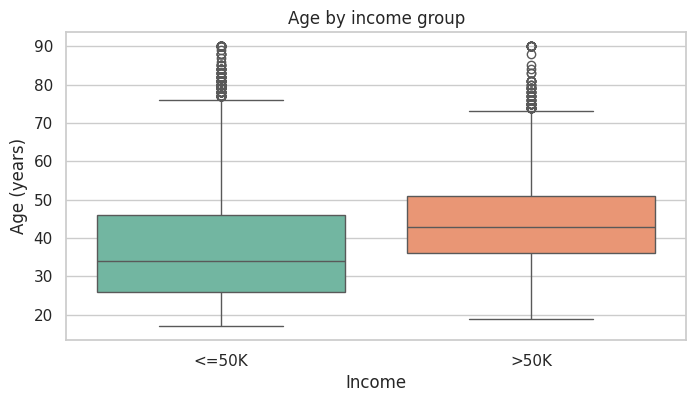

income
<=50K    34.0
>50K     43.0
Name: age, dtype: float64


In [ ]:
# Covariation between a numeric and the target: age by income group
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="income", y="age", hue="income", palette="Set2", legend=False)
plt.xticks([0, 1], ["<=50K", ">50K"])
plt.title("Age by income group"); plt.xlabel("Income"); plt.ylabel("Age (years)")
plt.show()
print(df.groupby("income")["age"].median().rename({0: "<=50K", 1: ">50K"}))

**Interpretation:** people earning >50K are clearly **older** on average (higher median age), and the young group under 25 is almost entirely <=50K. Income rises with age and experience.

## C3. Supporting questions
Each question is about **income inequality**, the problem chosen in Part A.

### Q1. Does more education mean higher income?

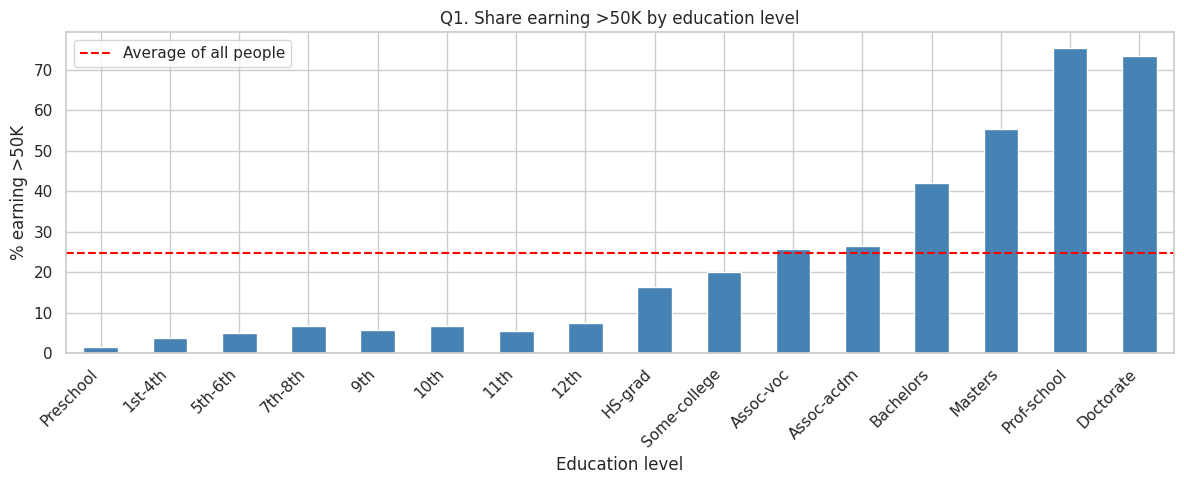

education_num
HS-grad      16.3
Bachelors    42.0
Masters      55.4
Doctorate    73.3
Name: income, dtype: float64


In [ ]:
# % of people earning >50K at each education level
edu_rate = df.groupby("education_num")["income"].mean().mul(100)
edu_rate.index = edu_rate.index.map(edu_names)       # numbers -> names

ax = edu_rate.plot(kind="bar", figsize=(12, 5), color="steelblue")
ax.axhline(df["income"].mean() * 100, color="red", ls="--", label="Average of all people")
ax.set(title="Q1. Share earning >50K by education level", xlabel="Education level",
       ylabel="% earning >50K")
ax.legend(handles=[ax.lines[0]], loc="upper left"); plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

print(edu_rate.round(1)[["HS-grad", "Bachelors", "Masters", "Doctorate"]])

**Answer: Yes.** The share of high earners rises almost steadily with education. It is very low for people who did not finish high school, stays below average for **HS-grad** and **Some-college**, and rises sharply from **Bachelors** upwards. More than **70%** of people with a **Doctorate** or **Prof-school** degree earn >50K, compared with under 20% of high-school graduates. Education is one of the strongest single drivers of income in this data.

### Q2. Is there an income gap between men and women?

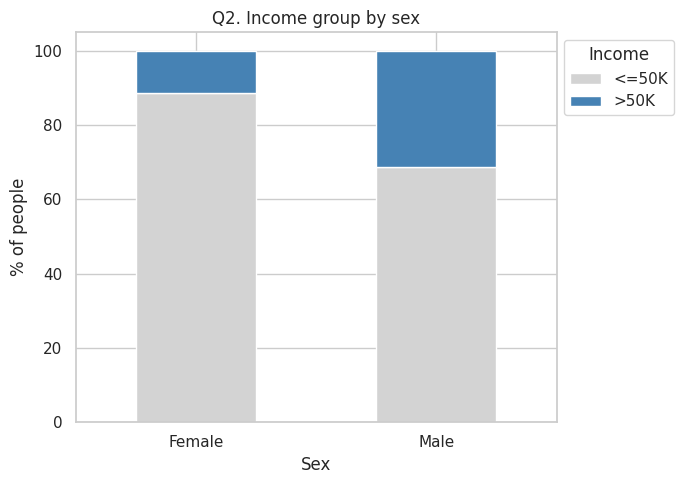

        <=50K  >50K
sex                
Female   88.6  11.4
Male     68.7  31.3
Men are 2.7 times as likely as women to earn >50K


In [ ]:
# Row percentages: within each sex, what share earns <=50K and >50K?
sex_tab = pd.crosstab(df["sex"], df["income"], normalize="index").mul(100)
sex_tab.columns = ["<=50K", ">50K"]

ax = sex_tab.plot(kind="bar", stacked=True, figsize=(7, 5), color=["lightgray", "steelblue"])
ax.set(title="Q2. Income group by sex", xlabel="Sex", ylabel="% of people")
plt.xticks(rotation=0); plt.legend(title="Income", bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

print(sex_tab.round(1))
ratio = sex_tab.loc["Male", ">50K"] / sex_tab.loc["Female", ">50K"]
print(f"Men are {ratio:.1f} times as likely as women to earn >50K")

**Answer: Yes, there is a large gap.** Men are roughly **three times** as likely as women to earn >50K (about 3 in 10 men compared with about 1 in 10 women). Part of the gap may come from differences in hours worked, jobs and marital roles (see C4), but the size of the difference shows a clear inequality by sex.

### Q3. Do people who work more hours earn more?

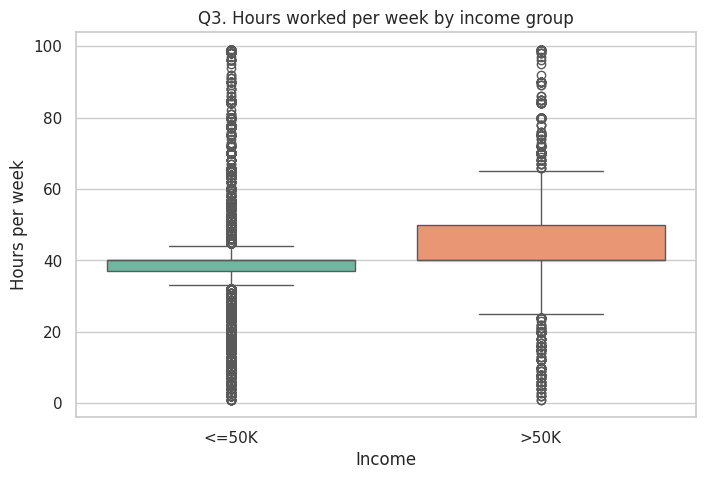

        mean   25%   50%   75%
income                        
<=50K   39.4  37.0  40.0  40.0
>50K    45.7  40.0  40.0  50.0

% earning >50K:
hours_per_week
Under 40       9.7
Exactly 40    21.8
Over 40       40.4
Name: income, dtype: float64


In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="income", y="hours_per_week", hue="income", palette="Set2", legend=False)
plt.xticks([0, 1], ["<=50K", ">50K"])
plt.title("Q3. Hours worked per week by income group")
plt.xlabel("Income"); plt.ylabel("Hours per week")
plt.show()

print(df.groupby("income")["hours_per_week"].describe()[["mean", "25%", "50%", "75%"]]
        .rename(index={0: "<=50K", 1: ">50K"}).round(1))

# Share of >50K among people working more vs less than 40 hours
print("\n% earning >50K:")
print(df.groupby(pd.cut(df["hours_per_week"], [0, 39, 40, 99],
                        labels=["Under 40", "Exactly 40", "Over 40"]),
                 observed=True)["income"].mean().mul(100).round(1))

**Answer: Yes, but only partly.** People earning >50K work **more hours** on average, and the middle 50% of their box sits higher. The share of high earners is much bigger among people working **over 40 hours** than among part-time workers. However, both groups have the **same typical value of 40 hours**, and the boxes overlap a lot, so hours alone do not explain income: many people work long hours and still earn <=50K.

### Q4. Does marital status affect income?

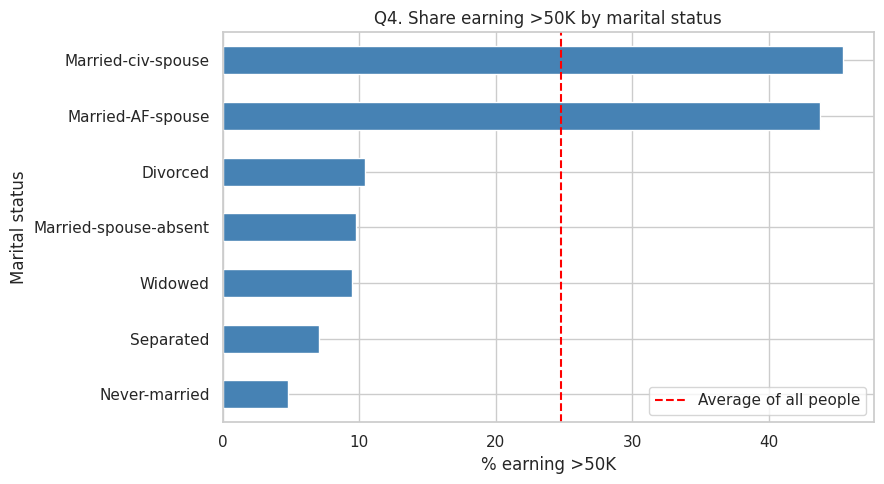

                       % >50K  people
marital_status                       
Never-married             4.8   14567
Separated                 7.0    1411
Widowed                   9.5    1277
Married-spouse-absent     9.8     552
Divorced                 10.4    6294
Married-AF-spouse        43.8      32
Married-civ-spouse       45.4   21042


In [ ]:
mar_rate = df.groupby("marital_status")["income"].mean().mul(100).sort_values()

ax = mar_rate.plot(kind="barh", figsize=(9, 5), color="steelblue")
ax.axvline(df["income"].mean() * 100, color="red", ls="--", label="Average of all people")
ax.set(title="Q4. Share earning >50K by marital status", xlabel="% earning >50K", ylabel="Marital status")
ax.legend(handles=[ax.lines[0]], loc="lower right"); plt.tight_layout(); plt.show()

print(pd.DataFrame({"% >50K": mar_rate.round(1),
                    "people": df["marital_status"].value_counts()}).sort_values("% >50K"))

**Answer: Yes, strongly.** People who are **married and living with a spouse** (Married-civ-spouse) are far more likely to earn >50K than any other group, while **Never-married** people have the lowest share. This does not mean marriage *causes* higher income: married people are also **older** (see C2) and, in this data, are mostly **men** (see C4). The *Married-AF-spouse* group (armed-forces spouse) is very small, so its figure is not reliable.

## C4. Unusual patterns
The code below backs up each pattern with numbers.

In [ ]:
# 1 and 2: census cap values
print("capital_gain = 99,999:", (df["capital_gain"] == 99999).sum(), "people")
print("  next-highest value:", df.loc[df["capital_gain"] < 99999, "capital_gain"].max())
print("hours_per_week = 99:", (df["hours_per_week"] == 99).sum(), "people")
print("  people at 98 hours:", (df["hours_per_week"] == 98).sum())

capital_gain = 99,999: 229 people
  next-highest value: 41310
hours_per_week = 99: 123 people
  people at 98 hours: 14


Relationship of married-civ-spouse people (%):
relationship
Husband           88.6
Wife               9.8
Other-relative     0.9
Own-child          0.6
Not-in-family      0.1
Name: proportion, dtype: float64

% earning >50K by relationship:
relationship
Wife              48.6
Husband           45.6
Not-in-family     10.5
Unmarried          6.3
Other-relative     3.7
Own-child          1.6
Name: income, dtype: float64


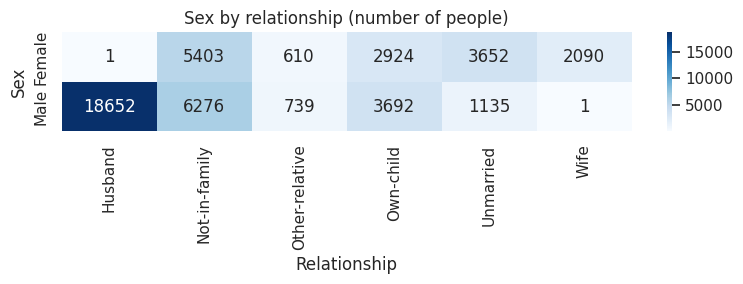

Female 'Husband' or Male 'Wife' records: 2


,age,sex,relationship,marital_status,income
530,29,Male,Wife,Married-civ-spouse,1
6549,34,Female,Husband,Married-civ-spouse,0


In [ ]:
# 3: marriage, relationship and sex are tied together
print("Relationship of married-civ-spouse people (%):")
print(df.loc[df["marital_status"] == "Married-civ-spouse", "relationship"]
        .value_counts(normalize=True).mul(100).round(1))

print("\n% earning >50K by relationship:")
print(df.groupby("relationship")["income"].mean().mul(100).round(1).sort_values(ascending=False))

# Heatmap: sex vs relationship (counts)
plt.figure(figsize=(8, 3))
sns.heatmap(pd.crosstab(df["sex"], df["relationship"]), annot=True, fmt="d", cmap="Blues")
plt.title("Sex by relationship (number of people)"); plt.xlabel("Relationship"); plt.ylabel("Sex")
plt.tight_layout(); plt.show()

# Records that do not match: a Female "Husband" or a Male "Wife"
odd = df[((df["relationship"] == "Husband") & (df["sex"] == "Female")) |
         ((df["relationship"] == "Wife") & (df["sex"] == "Male"))]
print("Female 'Husband' or Male 'Wife' records:", len(odd))
if len(odd):
    display(odd[["age", "sex", "relationship", "marital_status", "income"]])

In [ ]:
# 4 and 5: imbalance in sex and income
print("Men per woman:", round((df["sex"] == "Male").sum() / (df["sex"] == "Female").sum(), 2))
print("Income split (%):", df["income"].value_counts(normalize=True).mul(100).round(1)
      .rename({0: "<=50K", 1: ">50K"}).to_dict())

Men per woman: 2.08
Income split (%): {'<=50K': 75.2, '>50K': 24.8}


**Unusual patterns found:**
1. **`capital_gain = 99,999`** appears for a group of people while no one has values just below it (there is a large jump from the next-highest value). This is a **census cap**: it means "very high gain", not an exact amount.
2. **`hours_per_week = 99`** has far more people than 98 or 97. It is also a **cap** for "99 or more hours", so long working weeks are bunched at one value.
3. **Marital status, relationship and sex overlap.** Almost all *Married-civ-spouse* people are recorded as **Husband** or **Wife**, and *Husband* is male in almost every record. *Husband* and *Wife* have the highest share of high earners. So `marital_status`, `relationship` and `sex` carry much of the **same information**, and part of the "marriage effect" in Q4 is really an effect of sex and age.
4. **Men outnumber women about 2 to 1.** Results for women are based on a smaller group, and the sample does not mirror the real population.
5. **Income is imbalanced (about 75/25).** Later models need to be judged with measures beyond accuracy (for example precision and recall).
6. **Sex and relationship do not always agree.** The code above lists any records of a **Female "Husband"** or a **Male "Wife"**. Only 2 such records were found, and they look like **data-entry errors**. They are too few to affect the results, so they were kept, but they show that census answers were not fully checked.

## C5. Summary of findings

In [ ]:
# Key findings, all calculated from the data
from IPython.display import Markdown, display
s = df.groupby("sex")["income"].mean() * 100
e = df.groupby("education_num")["income"].mean() * 100
m = df.groupby("marital_status")["income"].mean() * 100
h = df.groupby("income")["hours_per_week"].mean()
top = corr["income"].drop("income").sort_values(ascending=False)
odd_n = len(odd)

bullets = f"""**Main findings (exact figures from the data):**
- **Education** is the strongest single factor: **{e[16]:.1f}%** of Doctorate holders earn >50K, compared with **{e[9]:.1f}%** of high-school graduates. Its correlation with income is **{top['education_num']:.2f}**.
- **Gender gap:** **{s['Male']:.1f}%** of men earn >50K, compared with **{s['Female']:.1f}%** of women (**{s['Male']/s['Female']:.1f} times** as likely).
- **Hours:** people earning >50K work **{h[1]:.1f}** hours a week on average, compared with **{h[0]:.1f}** for <=50K, but both groups typically work 40 hours.
- **Marital status:** **{m['Married-civ-spouse']:.1f}%** of married people earn >50K, compared with **{m['Never-married']:.1f}%** of never-married people. This is mixed up with sex and age, because most married people in the data are husbands.
- **Data issues:** only **{df['income'].mean()*100:.1f}%** earn >50K (imbalanced), there are **{(df['sex']=='Male').sum()/(df['sex']=='Female').sum():.1f}** men per woman, and cap values exist (**{(df['capital_gain']==99999).sum()}** people at capital_gain = 99,999; **{(df['hours_per_week']==99).sum()}** at 99 hours)."""
display(Markdown(bullets))

**Main findings (exact figures from the data):**
- **Education** is the strongest single factor: **73.3%** of Doctorate holders earn >50K, compared with **16.3%** of high-school graduates. Its correlation with income is **0.33**.
- **Gender gap:** **31.3%** of men earn >50K, compared with **11.4%** of women (**2.7 times** as likely).
- **Hours:** people earning >50K work **45.7** hours a week on average, compared with **39.4** for <=50K, but both groups typically work 40 hours.
- **Marital status:** **45.4%** of married people earn >50K, compared with **4.8%** of never-married people. This is mixed up with sex and age, because most married people in the data are husbands.
- **Data issues:** only **24.8%** earn >50K (imbalanced), there are **2.1** men per woman, and cap values exist (**229** people at capital_gain = 99,999; **123** at 99 hours).

# Part D: Encoding and PCA (Task 3)

## D0. Load the clean data

In [ ]:
from sklearn.preprocessing import StandardScaler   # scales every column to mean 0, std 1
from sklearn.decomposition import PCA              # principal component analysis

# Load the cleaned data from Part B
df = pd.read_csv("adult_clean.csv")

# Text (categorical) columns that must be encoded before PCA
cat_cols = df.select_dtypes(include="object").columns.tolist()
print("Shape:", df.shape)
print("Categorical columns and number of categories:")
print(df[cat_cols].nunique().sort_values())

Shape: (45175, 15)
Categorical columns and number of categories:
sex                2
race               5
relationship       6
age_group          6
workclass          7
marital_status     7
occupation        14
native_country    41
dtype: int64


## D1. Encoding
PCA only works with numbers, so every text column is converted. Each column gets the method that matches its type:

| Column | Method | Reason |
|---|---|---|
| `sex` | Label encoding (Male = 1, Female = 0) | Only two values, so one 0/1 column is enough |
| `age_group` | Ordinal encoding (0–5) | The groups have a natural order (younger → older) |
| `native_country` | Binary (United States = 1, other = 0) | About 90% are from the US; 41 one-hot columns would add many almost-empty columns |
| `workclass`, `marital_status`, `occupation`, `relationship`, `race` | One-hot encoding | No natural order; label numbers (1, 2, 3…) would wrongly suggest a ranking |
| `education_num` | Already numeric | Already ordered 1–16 |

In [ ]:
enc = df.copy()                       # keep df unchanged
cols_before = enc.shape[1]

# 1. Label encoding: sex -> 0/1
enc["sex"] = enc["sex"].map({"Male": 1, "Female": 0})

# 2. Ordinal encoding: age_group keeps its order (0 = youngest)
age_map = {"17-25": 0, "26-35": 1, "36-45": 2, "46-55": 3, "56-65": 4, "66+": 5}
enc["age_group"] = enc["age_group"].map(age_map)

# 3. Binary encoding: born in the United States or not
print("Share born in the US: {:.1f}%".format((enc["native_country"] == "United-States").mean() * 100))
enc["native_country"] = (enc["native_country"] == "United-States").astype(int)

# 4. One-hot encoding: one new 0/1 column per category
nominal = ["workclass", "marital_status", "occupation", "relationship", "race"]
enc = pd.get_dummies(enc, columns=nominal, dtype=int)

print(f"Columns before encoding: {cols_before}   after encoding: {enc.shape[1]}")
print("Any text columns left:", enc.select_dtypes(include="object").shape[1])
enc.head()

Share born in the US: 91.3%
Columns before encoding: 15   after encoding: 49
Any text columns left: 0


,age,education_num,sex,capital_gain,capital_loss,hours_per_week,native_country,income,age_group,has_capital_gain,...,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,race_Other,race_White
0,39,13,1,2174,0,40,1,0,2,1,...,1,0,0,0,0,0,0,0,0,1
1,50,13,1,0,0,13,1,0,3,0,...,0,0,0,0,0,0,0,0,0,1
2,38,9,1,0,0,40,1,0,2,0,...,1,0,0,0,0,0,0,0,0,1
3,53,7,1,0,0,40,1,0,3,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,0,40,0,0,1,0,...,0,0,0,0,1,0,0,1,0,0


In [ ]:
# Example: how one-hot encoding turns one 'race' column into several 0/1 columns
race_cols = [c for c in enc.columns if c.startswith("race_")]
pd.concat([df["race"].head(5), enc[race_cols].head(5)], axis=1)

,race,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,race_Other,race_White
0,White,0,0,0,0,1
1,White,0,0,0,0,1
2,White,0,0,0,0,1
3,Black,0,0,1,0,0
4,Black,0,0,1,0,0


**Interpretation:** PCA needs numbers, so I changed all the text columns into numbers. Sex only has two options, so I used 1 for Male and 0 for Female. Age groups go from young to old, so I numbered them 0 to 5 to keep that order. For native country, I used 1 for the United States and 0 for every other country. Most people in the data are from the US, and giving each of the 41 countries its own column would add too many columns that are almost all zeros. Workclass, marital status, occupation, relationship and race have no order, so I used one-hot encoding, which gives each category its own 0/1 column. If I had used numbers like 1, 2, 3, the model would think one job or race is "higher" than another, which is not true. After encoding, the data went from 15 to 49 columns.

## D2. Prepare the data for PCA
- **`income` is removed** from the inputs. PCA is unsupervised: it looks for structure in the features only. Income is kept aside to colour the charts.
- **All columns are scaled** with `StandardScaler`. PCA follows variance, so without scaling `capital_gain` (0–99,999) would dominate columns such as `sex` (0–1).

In [ ]:
y = enc["income"]                      # target, used only for colouring charts
X = enc.drop(columns=["income"])       # features for PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)     # each column now has mean 0 and std 1

print("Feature matrix:", X_scaled.shape)
print("Variance before scaling: capital_gain = {:,.0f}, sex = {:.2f}".format(X["capital_gain"].var(), X["sex"].var()))
print("Mean / std after scaling (first column): {:.2f} / {:.2f}".format(X_scaled[:, 0].mean(), X_scaled[:, 0].std()))

Feature matrix: (45175, 48)
Variance before scaling: capital_gain = 56,403,853, sex = 0.22
Mean / std after scaling (first column): 0.00 / 1.00


## D3. Apply PCA and choose the number of components

In [ ]:
pca = PCA()                            # keep all components first
pca.fit(X_scaled)

var = pca.explained_variance_ratio_    # share of variance explained by each component
cum = np.cumsum(var)                   # running total

k80 = int(np.argmax(cum >= 0.80) + 1)  # first component count that reaches 80%
k90 = int(np.argmax(cum >= 0.90) + 1)
print(f"Original features: {X.shape[1]}")
print(f"Components needed for 80% of the variance: {k80}")
print(f"Components needed for 90% of the variance: {k90}")

# Variance table for the first 10 components
pd.DataFrame({"component": [f"PC{i}" for i in range(1, 11)],
              "variance %": (var[:10] * 100).round(2),
              "cumulative %": (cum[:10] * 100).round(2)})

Original features: 48
Components needed for 80% of the variance: 28
Components needed for 90% of the variance: 33


,component,variance %,cumulative %
0,PC1,9.06,9.06
1,PC2,5.52,14.58
2,PC3,4.48,19.06
3,PC4,4.08,23.14
4,PC5,3.44,26.59
5,PC6,3.26,29.84
6,PC7,3.02,32.87
7,PC8,2.93,35.80
8,PC9,2.72,38.51
9,PC10,2.61,41.13


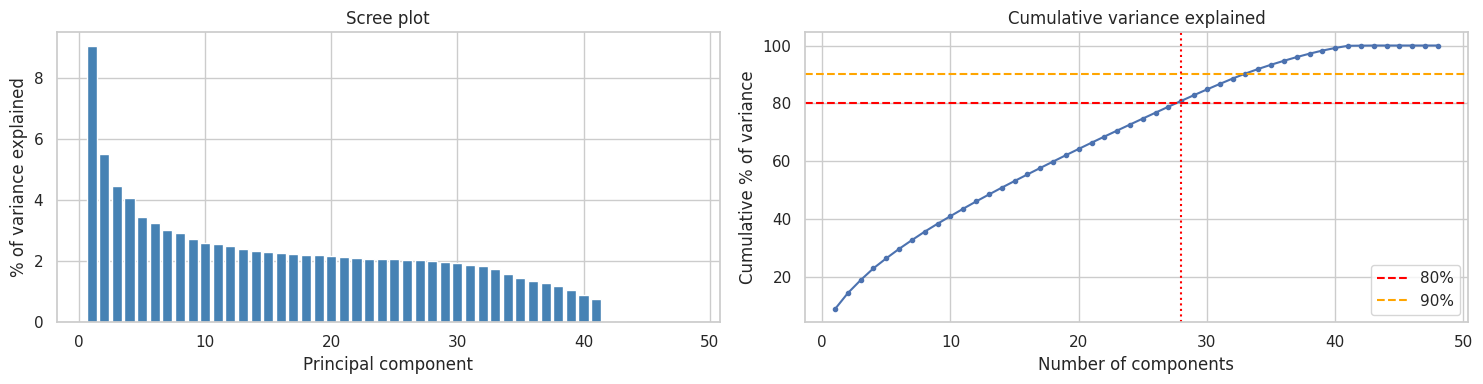

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Scree plot: variance explained by each component
axes[0].bar(range(1, len(var) + 1), var * 100, color="steelblue")
axes[0].set(title="Scree plot", xlabel="Principal component", ylabel="% of variance explained")

# Cumulative variance with the 80% and 90% lines
axes[1].plot(range(1, len(cum) + 1), cum * 100, marker="o", ms=3)
axes[1].axhline(80, color="red", ls="--", label="80%")
axes[1].axhline(90, color="orange", ls="--", label="90%")
axes[1].axvline(k80, color="red", ls=":")
axes[1].set(title="Cumulative variance explained", xlabel="Number of components", ylabel="Cumulative % of variance")
axes[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# Reduce the data to the chosen number of components (80% of the variance)
pca_k = PCA(n_components=k80)
X_pca = pca_k.fit_transform(X_scaled)
print(f"Data reduced from {X.shape[1]} columns to {X_pca.shape[1]} components, "
      f"keeping {pca_k.explained_variance_ratio_.sum() * 100:.1f}% of the variance")

Data reduced from 48 columns to 28 components, keeping 80.9% of the variance


**Interpretation:** To keep 80% of the information (variance), PCA needs 28 components out of 48 columns. To keep 90%, it needs 33. I went with 80% and 28 components, which cuts the columns by about 40% but still keeps most of the information. PC1 carries the most information (about 9%) and PC2 comes next (about 5.5%). After the first four components the bars drop a little, and then each component adds only about 2–3%. This is because most of my columns are one-hot 0/1 columns that don't have much to do with each other, so each one adds a small bit of new information. The last few components add almost nothing, which means some columns repeat information. In each one-hot group, you can always work out one column from the others. Also, `age_group` and `has_capital_gain` repeat what `age` and `capital_gain` already show.

## D4. Interpreting the components
**Loadings** show how strongly each original column contributes to a component. A large positive or negative loading means the column matters for that component.

In [ ]:
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])

# Top 6 columns for each of the first three components (largest absolute loading)
for pc in ["PC1", "PC2", "PC3"]:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(6)
    print(pc, f"({var[int(pc[2]) - 1] * 100:.1f}% of variance)")
    print(top.round(2).to_string(), "\n")

PC1 (9.1% of variance)
marital_status_Married-civ-spouse    0.41
relationship_Husband                 0.41
marital_status_Never-married        -0.35
age                                  0.30
age_group                            0.29
sex                                  0.25 

PC2 (5.5% of variance)
age                        0.35
age_group                  0.34
marital_status_Divorced    0.31
sex                       -0.30
relationship_Unmarried     0.29
marital_status_Widowed     0.23 

PC3 (4.5% of variance)
race_White                   0.39
education_num                0.38
race_Black                  -0.30
occupation_Prof-specialty    0.27
workclass_Private           -0.25
native_country               0.25 



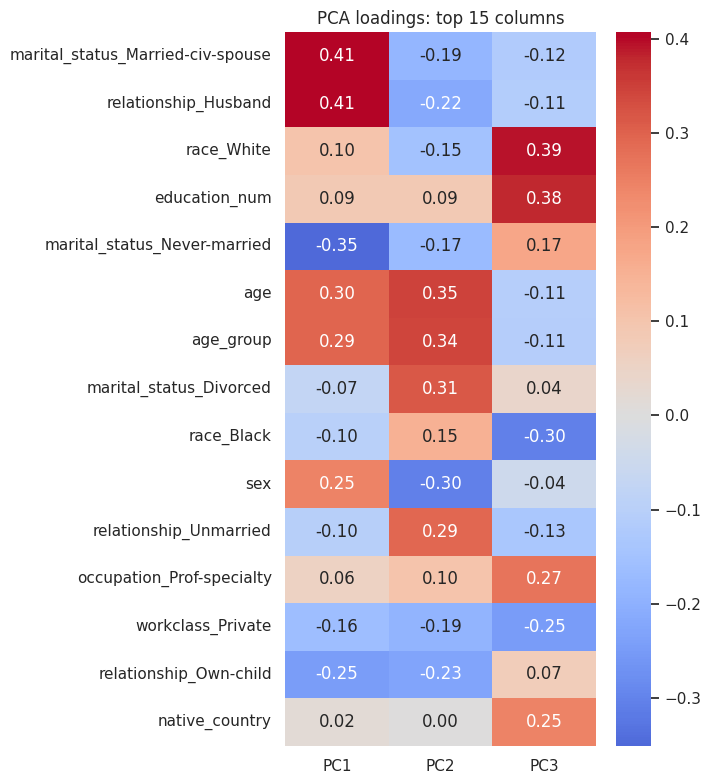

In [ ]:
# Heatmap of loadings for the 15 most important columns across PC1-PC3
top_cols = loadings.abs().max(axis=1).sort_values(ascending=False).head(15).index
plt.figure(figsize=(7, 8))
sns.heatmap(loadings.loc[top_cols], annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("PCA loadings: top 15 columns")
plt.tight_layout(); plt.show()

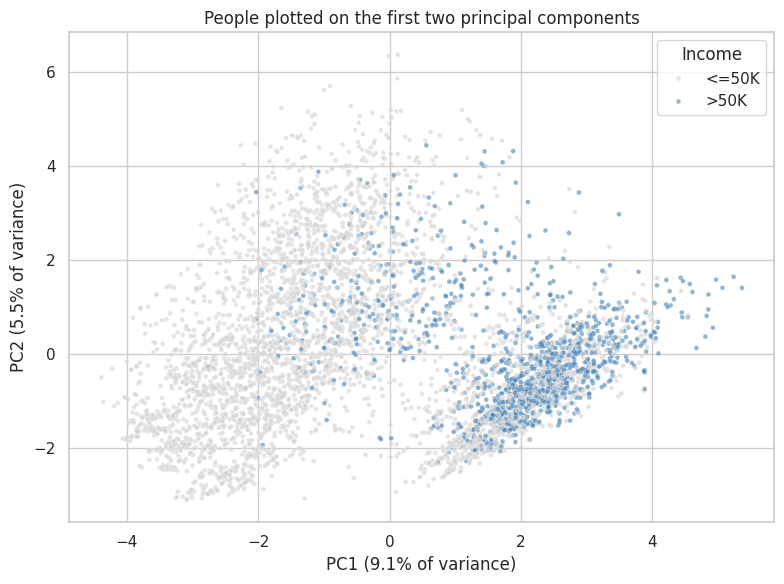

<=50K   -0.59
>50K     1.79
dtype: float64


In [ ]:
# PC1 vs PC2 for a random sample of 5,000 people, coloured by income
idx = np.random.default_rng(42).choice(len(X_scaled), 5000, replace=False)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[idx, 0], y=X_pca[idx, 1], hue=y.iloc[idx].map({0: "<=50K", 1: ">50K"}),
                palette={"<=50K": "lightgray", ">50K": "steelblue"}, alpha=0.6, s=12)
plt.title("People plotted on the first two principal components")
plt.xlabel(f"PC1 ({var[0] * 100:.1f}% of variance)")
plt.ylabel(f"PC2 ({var[1] * 100:.1f}% of variance)")
plt.legend(title="Income"); plt.tight_layout(); plt.show()

# Average PC1 score of each income group
print(pd.Series(X_pca[:, 0]).groupby(y.values).mean().rename({0: "<=50K", 1: ">50K"}).round(2))

**Interpretation:**

**PC1** is mostly about life stage and household role. Married people, husbands, older people and men score high on PC1. Never-married people and young people still living with their parents ("own-child") score low. So PC1 runs from young single people to older married men. This matches the EDA in Part C, where married people, husbands, older people and men had the highest share earning more than $50K.

**PC2** is about older people who live without a spouse. Divorced, widowed and unmarried people score high, and because `sex` is negative here, they are more often women.

**PC3** combines education, job type and background. People with more education, professional jobs, White people and those born in the US score high, while Black people and private-sector workers score lower.

In the scatter plot, people earning more than $50K (blue dots) are mostly on the right side of PC1, but they still overlap with the grey dots. This means PC1 (marriage, age and sex) is linked to higher income, but it does not fully separate high and low earners on its own.

Overall, PCA shows that the main patterns in the data come from marriage, age, sex, education and race, which are the same factors linked to income inequality in Part C.

## D5. Discussion

**Dimensionality reduction vs feature selection:** With feature selection, you pick which original columns to keep and drop the others. I did this in Part B when I removed `fnlwgt` and `education`. PCA works differently. It doesn't throw away any columns. It makes new columns, called principal components, and each one is a mix of all the original columns.

**Result:** PCA brought the data down from 48 columns to 28 components and still kept 80% of the information (variance).

**Limitations:** PCA can only pick up straight-line patterns in the data. A lot of my columns are one-hot 0/1 columns, and PCA works better with normal numbers. Also, the new components are harder to understand than the original columns like age or education, because each one is a mix of many columns.